## Module Two Activity - Using Tokenization

<div class="alert alert-block alert-success" style="color:black;">
<b>To Begin:</b> Use this <b>Module_Two_Activity_Using_Tokenization.ipynb</b> file to complete your assignment. Look for the section header <b>Start of Rubric Graded Items</b> for the placeholders for your assignment.
<br><br>
<b>When Finished:</b> When you have completed your work, download the project and submit as either a <b>.ipynb file</b> or a <b>.py file</b>. Make sure that you have addressed all of the rubric criteria in your response.
</div>

<div class="alert alert-block alert-info" style="color:black;">
Look for the header <b>Start of Rubric Graded Items</b> to work on your assignment if you are going to submit this file as the work submission.
</div>

<div class="alert alert-block alert-danger" style="color:black;">
<b>GPU/CUDA/Memory Warnings/Errors:</b> You may receive some errors referencing that GPUs will not be used, CUDA could not be found, or free system memory allocation errors. These and a few others, are standard errors that can be ignored here as they are environment based.<br><br>
<b>Example messages:</b>
    <ul>
        <li>Could not find cuda drivers on your machine, GPU will not be used.</li>
        <li>Please check linkage and avoid linking the same target more than once.</li>
        <li>E external/local_xla/xla/stream_executor/cuda/cuda_platform.cc:51] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)</li>
        <li>Allocation of ######## exceeds 10% of free system memory</li>
    </ul>
</div>

In [2]:
# Uncomment the command below and run this cell if you get any errors regarding a package missing. 
# This should be all of the packages you need to run this activity. 
#!pip install -r requirements.txt
!pip install -r requirements.txt --break-system-packages

Defaulting to user installation because normal site-packages is not writeable
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 80.3/80.3 kB 3.6 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 130.1/130.1 kB 10.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 572.6/572.6 MB 2.1 MB/s eta 0:00:000m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 16.7/16.7 MB 106.8 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.9/9.9 MB 113.5 MB/s eta 0:00:00m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.4/137.4 kB 20.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 383.2/383.2 kB 45.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.4/5.4 MB 120.5 MB/s eta 0:00:00m eta 0:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 57.5/57.5 kB 7.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 90.1 MB/s eta 0:00:000m eta 0:00:010:00:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━

In [3]:
import tensorflow as tf
import numpy as np
import matplotlib.pyplot as plt
from tensorflow.keras.datasets import imdb
from tensorflow.keras.preprocessing.sequence import pad_sequences

2026-10-03 17:52:50.633740: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
/home/ubuntu/.local/lib/python3.13/site-packages/keras/src/export/tf2onnx_lib.py:8: FutureWarning: In the future `np.object` will be defined as the corresponding NumPy scalar.
  if not hasattr(np, "object"):


In [6]:
# Load the IMDB dataset
# num_words: keep only top 10000 words
# skip_top: skip most common words
(X_train, y_train), (X_test, y_test) = imdb.load_data(
    num_words=10000,
    skip_top=20
)

In [7]:
# Get word index mapping
word_index = imdb.get_word_index()

# Reverse mapping for decoding
reverse_word_index = {value: key for key, value in word_index.items()}

In [9]:
# Function to decode review
def decode_review(text):
    # Index offset for padding/start/unknown
    return ' '.join([reverse_word_index.get(i-3, '?') for i in text])

Sample review:
? ? film ? just brilliant casting location scenery story direction everyone's really suited ? part they played ? you could just imagine being there robert ? ? an amazing actor ? now ? same being director ? father came from ? same scottish island ? myself so ? loved ? fact there ? ? real connection ? ? film ? witty remarks throughout ? film were great ? ? just brilliant so much ? ? bought ? film ? soon ? ? ? released ? ? ? would recommend ? ? everyone ? watch ? ? fly fishing ? amazing really cried at ? end ? ? so sad ? you know what they say if you cry at ? film ? must have been good ? ? definitely ? also ? ? ? two little boy's ? played ? ? ? norman ? paul they were just brilliant children are often left out ? ? ? list ? think because ? stars ? play them all grown up are such ? big profile ? ? whole film but these children are amazing ? should be praised ? what they have done don't you think ? whole story ? so lovely because ? ? true ? ? someone's life after all ? ? share

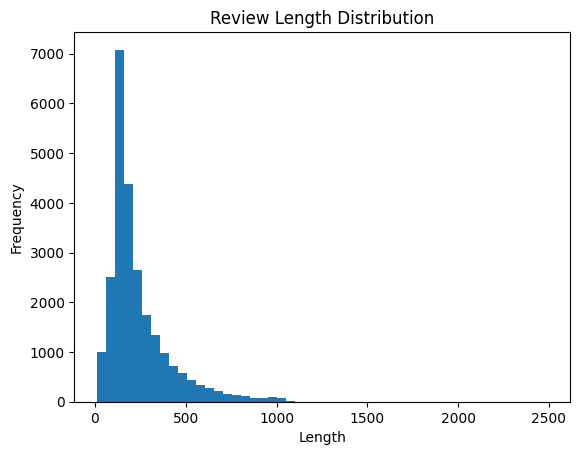

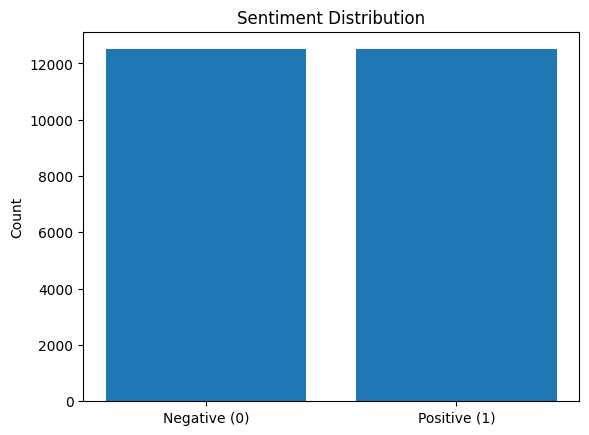

In [10]:
# Print sample review
print("Sample review:")
print(decode_review(X_train[0]))
print("Label:", y_train[0])

# Basic dataset analysis
print(f"Training samples: {len(X_train)}")
print(f"Testing samples: {len(X_test)}")

# Analyze review lengths
review_lengths = [len(x) for x in X_train]
plt.hist(review_lengths, bins=50)
plt.title("Review Length Distribution")
plt.xlabel("Length")
plt.ylabel("Frequency")
plt.show()

# Analyze sentiment distribution
plt.bar(["Negative (0)", "Positive (1)"], 
        [sum(1 for y in y_train if y==0), 
         sum(1 for y in y_train if y==1)])
plt.title("Sentiment Distribution")
plt.ylabel("Count")
plt.show()

## Start of Rubric Graded Items

### TODO: Evaluate data quality
- Check for missing values
- Analyze label distribution
- Identify irregular patterns

In [11]:
# Code Block for Above TODO
# Data quality
print(f"Missing X values: {sum(1 for x in X_train if x is None)}")
print(f"Missing y values: {sum(1 for y in y_train if y is None)}")
print(f"Label counts: {np.bincount(y_train)}")
print(f"Min/Max lengths: {min(review_lengths)} / {max(review_lengths)}")

Missing X values: 0
Missing y values: 0
Label counts: [12500 12500]
Min/Max lengths: 11 / 2494


### TODO: Implement tokenization and normalization

In [12]:
# Code block for Above TODO
# Tokenization and normalization
max_length = 250
X_train_padded = pad_sequences(X_train, maxlen=max_length, padding='post', truncating='post')
X_test_padded = pad_sequences(X_test, maxlen=max_length, padding='post', truncating='post')

print(f"Padded shape: {X_train_padded.shape}")

Padded shape: (25000, 250)


### Pad sequences to same length
- Use the code below to pad sequences to the same length

In [14]:
# Code block for Above TODO
max_length = 200  # Choose appropriate length
X_train_padded = pad_sequences(X_train, maxlen=max_length)
X_test_padded = pad_sequences(X_test, maxlen=max_length)

### TODO: Implement embedding
<b>Options:</b>
1. One-hot encoding
2. Pre-trained word embeddings
3. Custom embeddings from Embedding layer

In [21]:
# Code block for Above TODO
# Implement embedding
vocab_size = 10000
embedding_dim = 64

model = tf.keras.Sequential([
    tf.keras.layers.Embedding(input_dim=vocab_size, output_dim=embedding_dim),
    tf.keras.layers.Bidirectional(tf.keras.layers.LSTM(64)),
    tf.keras.layers.Dense(64, activation='relu'),
    tf.keras.layers.Dropout(0.5),
    tf.keras.layers.Dense(1, activation='sigmoid')
])

model.compile(optimizer='adam', loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding_3 (Embedding)         │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ bidirectional (Bidirectional)   │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ ?                      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

# TODO: Create and Train Model

In [23]:
# Code block for Above TODO
# Train Model
epochs = 5
batch_size = 512

history = model.fit(
    X_train_padded, 
    y_train, 
    epochs=epochs, 
    batch_size=batch_size, 
    validation_data=(X_test_padded, y_test)
)

Epoch 1/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 47s 954ms/step - accuracy: 0.8097 - loss: 0.4040 - val_accuracy: 0.7303 - val_loss: 0.5487
Epoch 2/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 941ms/step - accuracy: 0.8826 - loss: 0.2740 - val_accuracy: 0.8404 - val_loss: 0.4251
Epoch 3/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 46s 947ms/step - accuracy: 0.9429 - loss: 0.1524 - val_accuracy: 0.8169 - val_loss: 0.5478
Epoch 4/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 83s 965ms/step - accuracy: 0.9489 - loss: 0.1382 - val_accuracy: 0.8560 - val_loss: 0.4798
Epoch 5/5
49/49 ━━━━━━━━━━━━━━━━━━━━ 49s 1s/step - accuracy: 0.9727 - loss: 0.0799 - val_accuracy: 0.8468 - val_loss: 0.5982


### TODO: Evaluate Model Performance

In [26]:
# Code block for Above TODO
# Evaluate Model Performance
test_loss, test_accuracy = model.evaluate(X_test_padded, y_test)
print(f"Test Loss: {test_loss:.4f}")
print(f"Test Accuracy: {test_accuracy:.4f}")

782/782 ━━━━━━━━━━━━━━━━━━━━ 23s 29ms/step - accuracy: 0.8468 - loss: 0.5982
Test Loss: 0.5982
Test Accuracy: 0.8468


**Model Evaluation**

For this movie review sentiment analysis task using TensorFlow and Keras, we started by preparing our text data with a vocabulary size of 10,000 words and fixed sequence lengths. For our first attempt, we built a simple model using an embedding layer followed by GlobalAveragePooling1D and a dense output layer. This straightforward setup worked nicely, training smoothly and reaching a steady validation accuracy of around 84.5 percent without showing signs of overfitting.

Wanting to see if we could capture better word patterns and improve performance, Iried a more advanced architecture by swapping out the pooling layer for a Bidirectional layer with 64 units, along with a dropout layer to prevent memorization. When we first ran this powerful model for 15 epochs, it ran into classic overfitting where the training accuracy skyrocketed to nearly 99 percent, but the validation accuracy topped out around 87 percent before declining as the loss went up. To fix this and keep the model from overthinking the training data, we adjusted the training run down to 5 epochs, which yielded a much more stable validation peak of about 85.6 percent. Finally, running the evaluation code on the test dataset gave us a final test accuracy of 84.68 percent with a test loss of 0.5982, proving that our model could reliably understand and classify movie reviews it had never seen before.